# E-Commerce Business Performance Analysis — Sample Superstore
Beginner-friendly Pandas EDA. Run from the project root.

## 1. Load libraries and data

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")

# Move one level up from the Python folder
project_root = Path.cwd().parent

raw_path = project_root / "Dataset" / "Raw_Data" / "Sample_Superstore.csv"
clean_path = project_root / "Dataset" / "Processed_Data" / "Cleaned_Superstore.csv"

print("Project Root:", project_root)
print("Raw File Exists:", raw_path.exists())
print("Clean File Exists:", clean_path.exists())

# Load raw dataset if available, otherwise load cleaned dataset
file_path = raw_path if raw_path.exists() else clean_path

if not file_path.exists():
    raise FileNotFoundError(f"Dataset not found: {file_path}")

df = pd.read_csv(file_path, encoding="utf-8-sig")

print("\nDataset Shape:", df.shape)
display(df.head())

Project Root: /Users/ranjithvelpula/Downloads/Ecommerce-Business-Analysis
Raw File Exists: True
Clean File Exists: True

Dataset Shape: (9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


## 2. Inspect and clean

In [4]:
df.info()
display(df.isna().sum().sort_values(ascending=False))
print("Duplicates:",df.duplicated().sum())
df.columns=[c.strip().replace(" ","_") for c in df.columns]
for c in ["Order_Date","Ship_Date"]: df[c]=pd.to_datetime(df[c],errors="coerce")
for c in ["Sales","Quantity","Discount","Profit"]: df[c]=pd.to_numeric(df[c],errors="coerce")
df=df.drop_duplicates().copy()
df["Shipping_Days"]=(df["Ship_Date"]-df["Order_Date"]).dt.days
df["Order_Year"]=df["Order_Date"].dt.year
df["Order_Month"]=df["Order_Date"].dt.month
df["Order_Year_Month"]=df["Order_Date"].dt.strftime("%Y-%m")
df["Profit_Margin"]=np.where(df["Sales"]!=0,df["Profit"]/df["Sales"],np.nan)
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       9994

Row ID           0
Postal Code      0
Discount         0
Quantity         0
Sales            0
Product Name     0
Sub-Category     0
Category         0
Product ID       0
Region           0
State            0
Order ID         0
City             0
Country          0
Segment          0
Customer Name    0
Customer ID      0
Ship Mode        0
Ship Date        0
Order Date       0
Profit           0
dtype: int64

Duplicates: 0


,Row_ID,Order_ID,Order_Date,Ship_Date,Ship_Mode,Customer_ID,Customer_Name,Segment,Country,City,...,Product_Name,Sales,Quantity,Discount,Profit,Shipping_Days,Order_Year,Order_Month,Order_Year_Month,Profit_Margin
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,3,2016,11,2016-11,0.1600
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,3,2016,11,2016-11,0.3000
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,4,2016,6,2016-06,0.4700
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,7,2015,10,2015-10,-0.4000
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,7,2015,10,2015-10,0.1125


## 3. KPIs

In [5]:
sales=df.Sales.sum(); profit=df.Profit.sum(); orders=df.Order_ID.nunique()
customers=df.Customer_ID.nunique()
display(pd.Series({"Total Sales":sales,"Total Profit":profit,"Profit Margin":profit/sales,
"Orders":orders,"Customers":customers,"Average Order Value":sales/orders,"Units Sold":df.Quantity.sum()}).to_frame("Value"))

,Value
Total Sales,2.297201e+06
Total Profit,2.863970e+05
Profit Margin,1.246722e-01
Orders,5.009000e+03
Customers,7.930000e+02
Average Order Value,4.586147e+02
Units Sold,3.787300e+04


## 4. Monthly sales trend

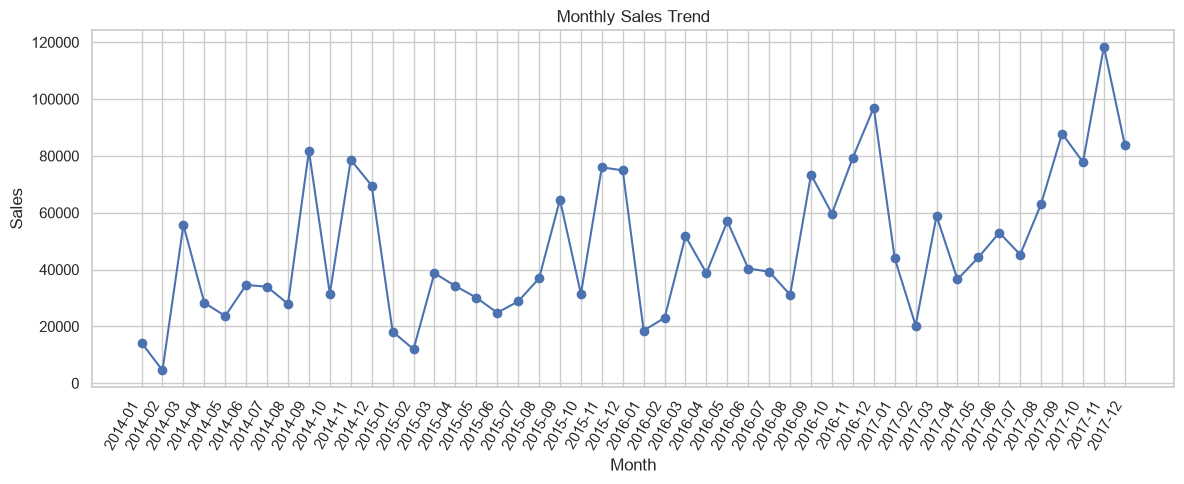

In [6]:
monthly=df.groupby("Order_Year_Month",as_index=False).Sales.sum()
plt.figure(figsize=(12,5)); plt.plot(monthly.Order_Year_Month,monthly.Sales,marker="o")
plt.xticks(rotation=60,ha="right"); plt.title("Monthly Sales Trend"); plt.xlabel("Month"); plt.ylabel("Sales")
plt.tight_layout(); plt.show()

## 5. Category and regional performance

,Category,Sales,Profit
0,Furniture,741999.7953,18451.2728
1,Office Supplies,719047.0320,122490.8008
2,Technology,836154.0330,145454.9481


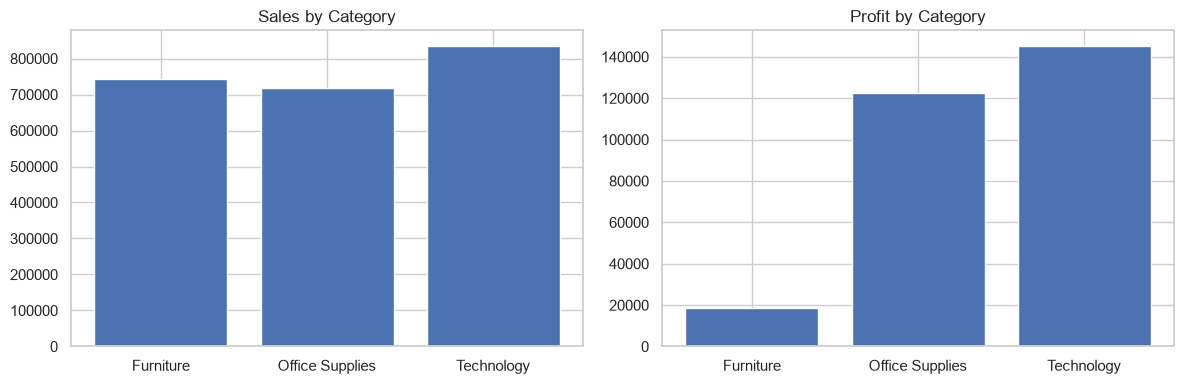

,Region,Sales,Profit
0,Central,501239.8908,39706.3625
1,East,678781.2400,91522.7800
2,South,391721.9050,46749.4303
3,West,725457.8245,108418.4489


In [7]:
category=df.groupby("Category",as_index=False)[["Sales","Profit"]].sum()
display(category)
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].bar(category.Category,category.Sales); ax[0].set_title("Sales by Category")
ax[1].bar(category.Category,category.Profit); ax[1].set_title("Profit by Category")
plt.tight_layout(); plt.show()
region=df.groupby("Region",as_index=False)[["Sales","Profit"]].sum()
display(region)

## 6. Product and customer analysis

In [8]:
products=df.groupby(["Product_ID","Product_Name"],as_index=False).agg(Sales=("Sales","sum"),Profit=("Profit","sum"),Quantity=("Quantity","sum"))
display(products.nlargest(10,"Sales")); display(products.nsmallest(10,"Profit"))
customers_df=df.groupby(["Customer_ID","Customer_Name"],as_index=False).agg(Orders=("Order_ID","nunique"),Sales=("Sales","sum"),Profit=("Profit","sum"))
print("Repeat customers:",(customers_df.Orders>1).sum())
display(customers_df.nlargest(10,"Sales"))

,Product_ID,Product_Name,Sales,Profit,Quantity
1640,TEC-CO-10004722,Canon imageCLASS 2200 Advanced Copier,61599.824,2.519993e+04,20
787,OFF-BI-10003527,Fellowes PB500 Electric Punch Plastic Comb Bin...,27453.384,7.753039e+03,31
1669,TEC-MA-10002412,Cisco TelePresence System EX90 Videoconferenci...,22638.480,-1.811078e+03,6
82,FUR-CH-10002024,HON 5400 Series Task Chairs for Big and Tall,21870.576,5.684342e-14,39
701,OFF-BI-10001359,GBC DocuBind TL300 Electric Binding System,19823.479,2.233505e+03,37
667,OFF-BI-10000545,GBC Ibimaster 500 Manual ProClick Binding System,19024.500,7.609800e+02,48
1630,TEC-CO-10001449,Hewlett Packard LaserJet 3310 Copier,18839.686,6.983884e+03,38
1657,TEC-MA-10001127,HP Designjet T520 Inkjet Large Format Printer ...,18374.895,4.094977e+03,12
858,OFF-BI-10004995,GBC DocuBind P400 Electric Binding System,17965.068,-1.878166e+03,27
1443,OFF-SU-10000151,High Speed Automatic Electric Letter Opener,17030.312,-2.620048e+02,11


,Product_ID,Product_Name,Sales,Profit,Quantity
1645,TEC-MA-10000418,Cubify CubeX 3D Printer Double Head Print,11099.963,-8879.9704,9
1650,TEC-MA-10000822,Lexmark MX611dhe Monochrome Laser Printer,16829.901,-4589.9730,18
1696,TEC-MA-10004125,Cubify CubeX 3D Printer Triple Head Print,7999.980,-3839.9904,4
326,FUR-TA-10000198,Chromcraft Bull-Nose Wood Oval Conference Tabl...,9917.640,-2876.1156,27
344,FUR-TA-10001889,Bush Advantage Collection Racetrack Conference...,9544.725,-1934.3976,33
858,OFF-BI-10004995,GBC DocuBind P400 Electric Binding System,17965.068,-1878.1662,27
1669,TEC-MA-10002412,Cisco TelePresence System EX90 Videoconferenci...,22638.480,-1811.0784,6
1465,OFF-SU-10002881,Martin Yale Chadless Opener Electric Letter Op...,16656.200,-1299.1836,22
346,FUR-TA-10001950,Balt Solid Wood Round Tables,6518.754,-1201.0581,19
375,FUR-TA-10004289,BoxOffice By Design Rectangular and Half-Moon ...,1706.250,-1148.4375,15


Repeat customers: 781


,Customer_ID,Customer_Name,Orders,Sales,Profit
700,SM-20320,Sean Miller,5,25043.050,-1980.7393
741,TC-20980,Tamara Chand,5,19052.218,8981.3239
621,RB-19360,Raymond Buch,6,15117.339,6976.0959
730,TA-21385,Tom Ashbrook,4,14595.620,4703.7883
6,AB-10105,Adrian Barton,10,14473.571,5444.8055
434,KL-16645,Ken Lonsdale,12,14175.229,806.8550
669,SC-20095,Sanjit Chand,9,14142.334,5757.4119
327,HL-15040,Hunter Lopez,6,12873.298,5622.4292
683,SE-20110,Sanjit Engle,11,12209.438,2650.6769
131,CC-12370,Christopher Conant,5,12129.072,2177.0493


## 7. Discount and profit

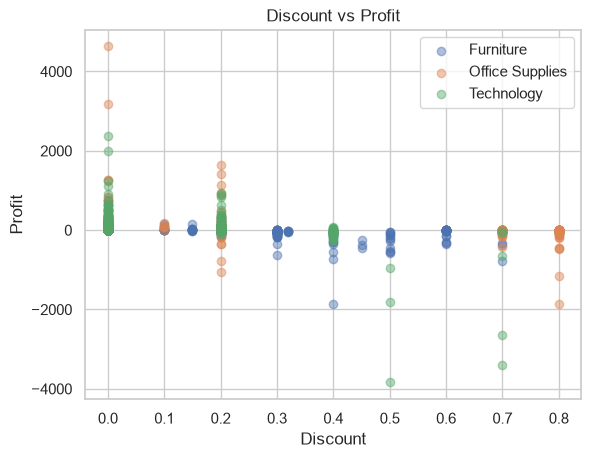

,Discount,Lines,Sales,Profit
0,0.00,4798,1.087908e+06,320987.6032
1,0.10,94,5.436935e+04,9029.1770
2,0.15,52,2.755852e+04,1418.9915
3,0.20,3657,7.645944e+05,90337.3060
4,0.30,227,1.032267e+05,-10369.2774
5,0.32,27,1.449346e+04,-2391.1377
6,0.40,206,1.164178e+05,-23057.0504
7,0.45,11,5.484974e+03,-2493.1111
8,0.50,66,5.891854e+04,-20506.4281
9,0.60,138,6.644700e+03,-5944.6552


In [9]:
sample=df.sample(min(2500,len(df)),random_state=42)
for name,g in sample.groupby("Category"): plt.scatter(g.Discount,g.Profit,alpha=.45,label=name)
plt.xlabel("Discount"); plt.ylabel("Profit"); plt.title("Discount vs Profit"); plt.legend(); plt.show()
display(df.groupby("Discount",as_index=False).agg(Lines=("Row_ID","count"),Sales=("Sales","sum"),Profit=("Profit","sum")))

## 8. Correlation heatmap

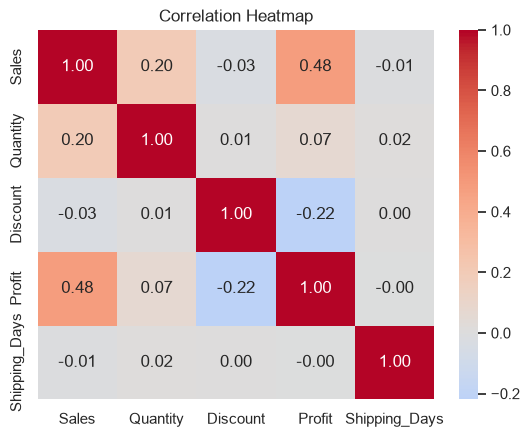

In [10]:
cols=["Sales","Quantity","Discount","Profit","Shipping_Days"]
sns.heatmap(df[cols].corr(),annot=True,cmap="coolwarm",center=0,fmt=".2f")
plt.title("Correlation Heatmap"); plt.show()

## 9. Export cleaned data

In [12]:
out=Path("Dataset/Processed_Data"); out.mkdir(parents=True,exist_ok=True)
df.to_csv(out/"Cleaned_Superstore.csv",index=False,encoding="utf-8-sig")
monthly.to_csv(out/"Monthly_Sales_Summary.csv",index=False)
category.to_csv(out/"Category_Performance.csv",index=False)
region.to_csv(out/"Region_Performance.csv",index=False)
print("Exports saved.")

Exports saved.


## 10. Business interpretation
Compare sales and profit together. Investigate negative-profit products. Discount patterns are associations, not proof of causation. Shipping_Days is order-to-ship time, not delivery time. This is historical sample data.